# Clase 11 · KNN, SVC con más de dos clases y redes neuronales

**INF-396 Introducción a la Ciencia de Datos** · Universidad Técnica Federico Santa María · viernes 20 de noviembre de 2026

**Qué hacemos hoy.** Tres clasificadores para problemas con más de dos clases. KNN (k-nearest neighbors) clasifica un dato nuevo con la clase de sus vecinos más cercanos. SVC, el clasificador de la clase 10, separa tres o más clases combinando clasificadores de a dos. Y una red neuronal pequeña, como primera mirada. Primero trabajamos con las tres especies de pingüinos, donde todo se puede dibujar, y después con 1.797 imágenes de dígitos escritos a mano, que tienen diez clases. Las lecturas son las secciones 2.2.3 y 9.4 de James, Witten, Hastie y Tibshirani (2013) y, para las redes neuronales, la sección 10.1 de la edición en Python del mismo libro (2023).

## 1. Preparación

De **scikit-learn** se usan `KNeighborsClassifier` (KNN), `SVC` (el clasificador de soporte vectorial de la clase 10) y `MLPClassifier` (una red neuronal), además de lo de las clases anteriores para separar, estandarizar, elegir parámetros y dibujar curvas ROC.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# scikit-learn: separar, estandarizar, elegir parámetros, evaluar y los modelos de hoy
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import load_digits

sns.set_theme(style="whitegrid")
%config InlineBackend.figure_format = "retina"
pd.options.display.float_format = "{:.3f}".format

In [2]:
# Datos locales del repositorio clonado
BASE = "datos/"
# Alternativa por URL, si no tiene el repositorio clonado:
# BASE = "https://raw.githubusercontent.com/daniopitz/cienciadatos/main/datos/"

## 2. Los pingüinos con las tres especies

Los mismos datos de las clases 08 y 10. Hoy se usan las tres especies y solo dos medidas, el largo y el alto del pico, para poder dibujar todo lo que hacen los clasificadores. Se quitan los pingüinos sin esas medidas.

En el gráfico, cada punto es un pingüino. Las tres especies forman tres nubes que se tocan en los bordes: ahí van a estar los errores.

In [3]:
pinguinos = pd.read_csv(BASE + "clase08/pinguinos_palmer.csv")
pico = ["largo_pico_mm", "alto_pico_mm"]
pinguinos = pinguinos.dropna(subset=pico).reset_index(drop=True)
pinguinos.head()

,especie,isla,largo_pico_mm,alto_pico_mm,largo_aleta_mm,masa_g,sexo,anio
0,Adelia,Torgersen,39.100,18.700,181.000,3750.000,macho,2007
1,Adelia,Torgersen,39.500,17.400,186.000,3800.000,hembra,2007
2,Adelia,Torgersen,40.300,18.000,195.000,3250.000,hembra,2007
3,Adelia,Torgersen,36.700,19.300,193.000,3450.000,hembra,2007
4,Adelia,Torgersen,39.300,20.600,190.000,3650.000,macho,2007


In [4]:
print("pingüinos:", len(pinguinos))
print("por especie:", pinguinos["especie"].value_counts().to_dict())
pinguinos[["especie"] + pico].head()

pingüinos: 342
por especie: {'Adelia': 151, 'Papúa': 123, 'Barbijo': 68}


,especie,largo_pico_mm,alto_pico_mm
0,Adelia,39.100,18.700
1,Adelia,39.500,17.400
2,Adelia,40.300,18.000
3,Adelia,36.700,19.300
4,Adelia,39.300,20.600


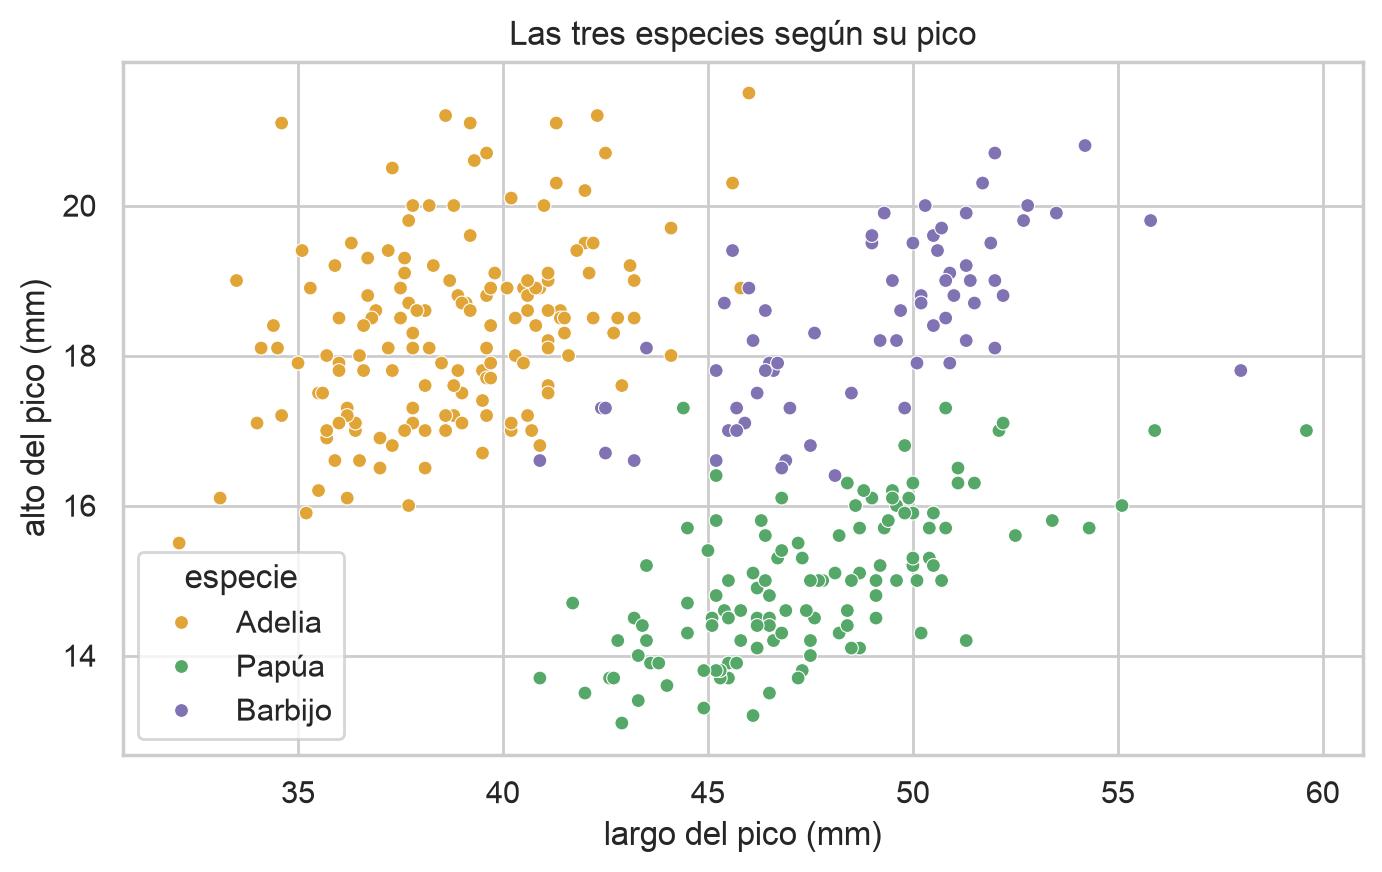

In [5]:
colores = {"Adelia": "#E0A437", "Barbijo": "#8172B3", "Papúa": "#55A868"}

plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=pinguinos, x="largo_pico_mm", y="alto_pico_mm", hue="especie", palette=colores, s=25)
plt.xlabel("largo del pico (mm)")
plt.ylabel("alto del pico (mm)")
plt.title("Las tres especies según su pico")
plt.show()

**Separar y estandarizar.** Se separa un 30 % de los pingüinos para la prueba, con la misma proporción de cada especie (`stratify`). Las dos medidas se estandarizan con la media y la desviación estándar del entrenamiento, como en la clase 10.

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(
    pinguinos[pico], pinguinos["especie"], test_size=0.3,
    random_state=396, stratify=pinguinos["especie"])

escala = StandardScaler().fit(X_tr)
Z_tr = escala.transform(X_tr)
Z_te = escala.transform(X_te)
print("entrenamiento:", len(X_tr), "| prueba:", len(X_te))

entrenamiento: 239 | prueba: 103


## 3. KNN: clasificar según los vecinos

**Objetivo:** clasificar un pingüino con la especie de los K pingüinos de entrenamiento que tiene más cerca.

**Un pingüino nuevo.** Tiene un pico de 43 mm de largo y 16,5 mm de alto, y queda entre las tres nubes. Para medir distancias se le aplica la misma estandarización.

In [7]:
nuevo = pd.DataFrame({"largo_pico_mm": [43.0], "alto_pico_mm": [16.5]})
nuevo

,largo_pico_mm,alto_pico_mm
0,43.000,16.500


In [8]:
z_nuevo = escala.transform(nuevo)
print("el pingüino nuevo, estandarizado:", z_nuevo.round(3))

el pingüino nuevo, estandarizado: [[-0.151 -0.305]]


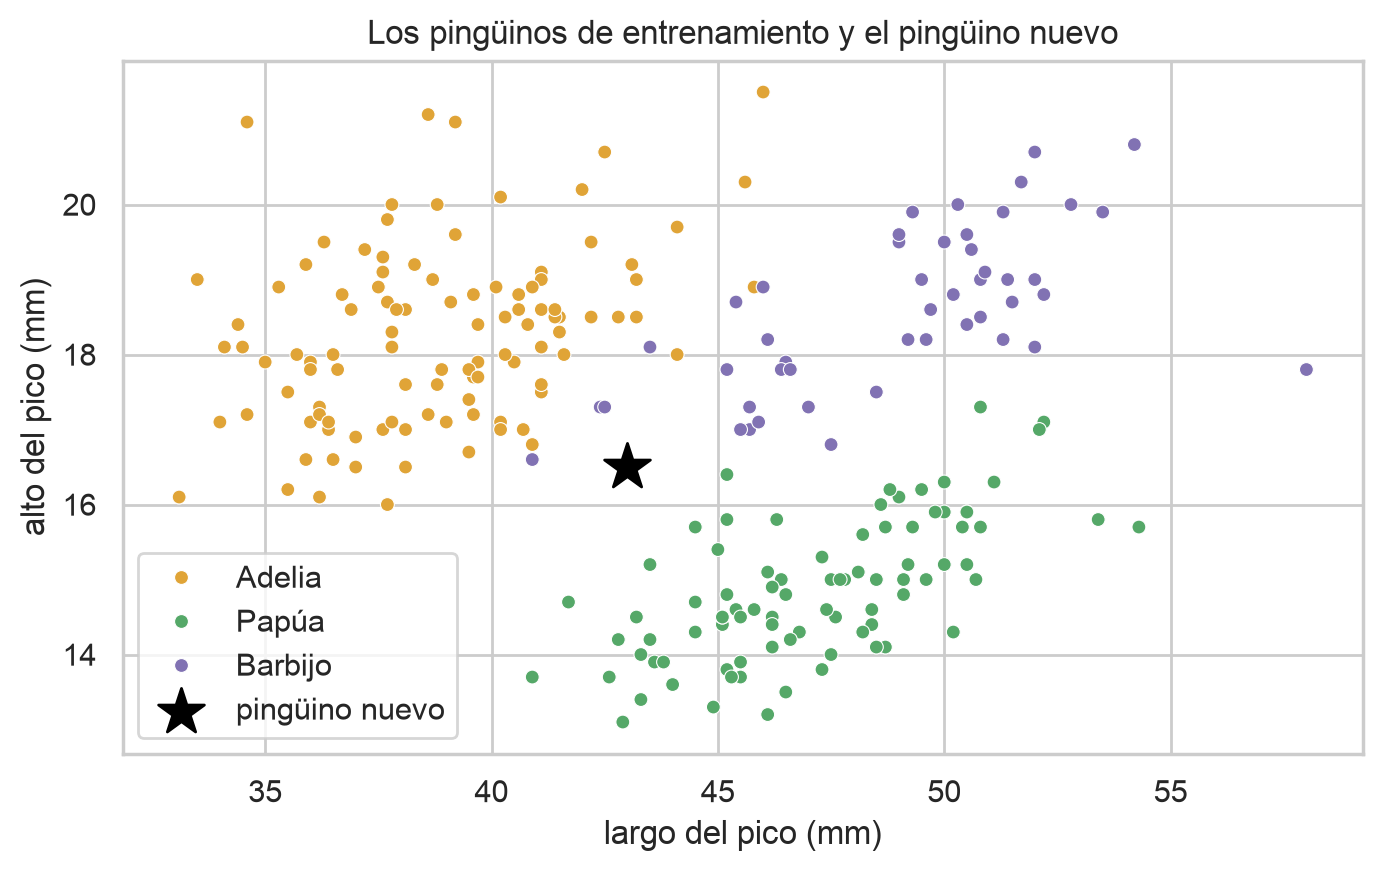

In [9]:
plt.figure(figsize=(8, 4.5))
sns.scatterplot(x=X_tr["largo_pico_mm"], y=X_tr["alto_pico_mm"], hue=y_tr, palette=colores, s=25)
plt.scatter(nuevo["largo_pico_mm"], nuevo["alto_pico_mm"], marker="*", s=300, color="black", label="pingüino nuevo")
plt.xlabel("largo del pico (mm)")
plt.ylabel("alto del pico (mm)")
plt.title("Los pingüinos de entrenamiento y el pingüino nuevo")
plt.legend()
plt.show()

**Sus vecinos.** `KNeighborsClassifier` no calcula nada al entrenar: `fit` solo guarda los pingüinos de entrenamiento. El trabajo ocurre al predecir. `kneighbors` entrega la distancia a los K vecinos más cercanos y su posición en la tabla de entrenamiento. Aquí K = 5.

Después de la tabla, los cinco vecinos en un gráfico con las medidas estandarizadas, que es donde se mide la distancia. El círculo tiene por radio la distancia al quinto vecino.

In [10]:
knn = KNeighborsClassifier(n_neighbors=5).fit(Z_tr, y_tr)
distancias, posiciones = knn.kneighbors(z_nuevo)



In [11]:
vecinos = X_tr.iloc[posiciones[0]].copy()
vecinos

,largo_pico_mm,alto_pico_mm
304,40.900,16.600
328,42.500,17.300
230,45.200,16.400
294,42.400,17.300
75,40.900,16.800


In [12]:
vecinos["especie"] = y_tr.iloc[posiciones[0]]
vecinos["distancia"] = distancias[0]
vecinos

,largo_pico_mm,alto_pico_mm,especie,distancia
304,40.900,16.600,Barbijo,0.397
328,42.500,17.300,Barbijo,0.413
230,45.200,16.400,Papúa,0.415
294,42.400,17.300,Barbijo,0.418
75,40.900,16.800,Adelia,0.421


In [13]:
z_vecinos = Z_tr[posiciones[0]]
z_vecinos

array([[-0.54431749, -0.25478931],
       [-0.24448026,  0.09720286],
       [ 0.26149508, -0.3553585 ],
       [-0.26322008,  0.09720286],
       [-0.54431749, -0.15422012]])

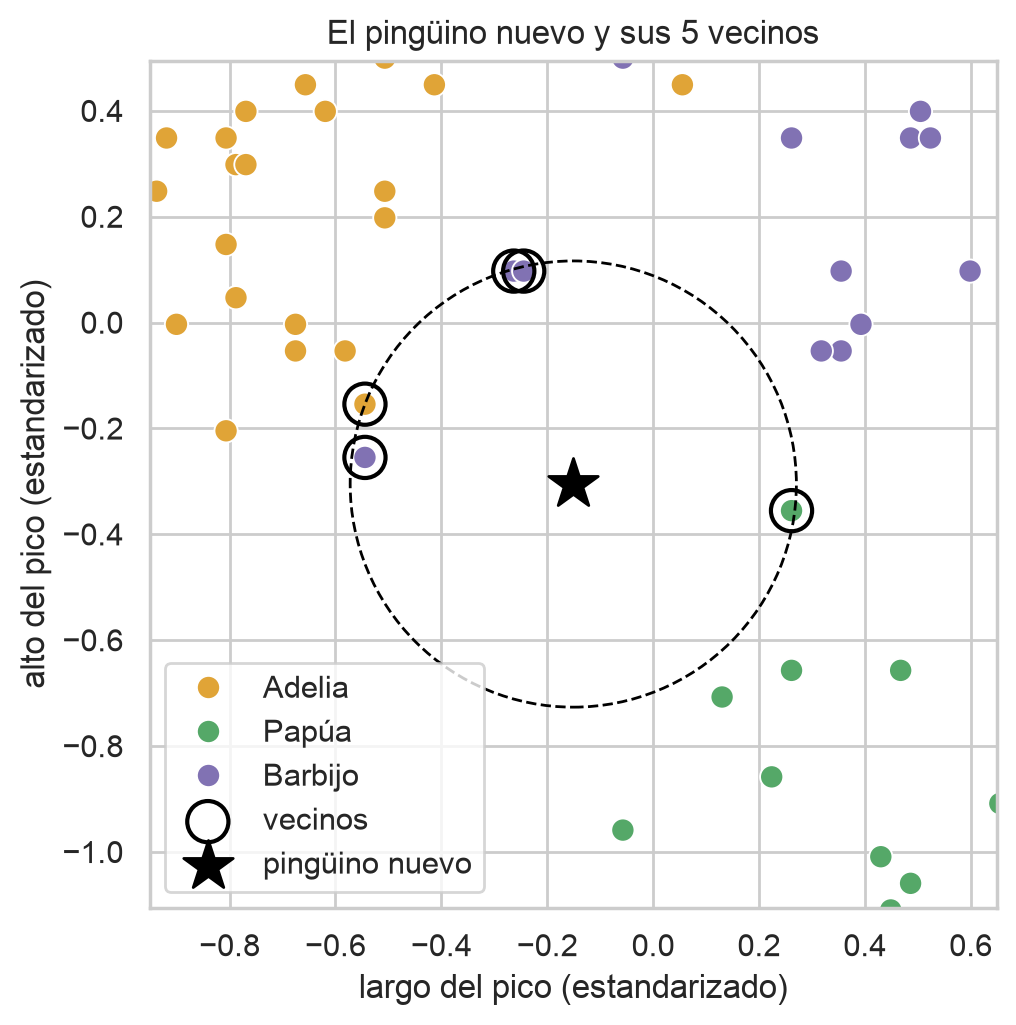

In [14]:
fig, eje = plt.subplots(figsize=(5.5, 5.5))
sns.scatterplot(x=Z_tr[:, 0], y=Z_tr[:, 1], hue=y_tr.values, palette=colores, s=70, ax=eje)
eje.scatter(z_vecinos[:, 0], z_vecinos[:, 1], s=220, facecolors="none", edgecolors="black", linewidths=1.5, label="vecinos")
eje.scatter(z_nuevo[0, 0], z_nuevo[0, 1], marker="*", s=350, color="black", label="pingüino nuevo")
eje.add_patch(plt.Circle((z_nuevo[0, 0], z_nuevo[0, 1]), distancias[0].max(), fill=False, linestyle="--", color="black"))

# un acercamiento alrededor del pingüino nuevo, con la misma escala en los dos ejes
eje.set_xlim(z_nuevo[0, 0] - 0.8, z_nuevo[0, 0] + 0.8)
eje.set_ylim(z_nuevo[0, 1] - 0.8, z_nuevo[0, 1] + 0.8)
eje.set_aspect("equal")
eje.set_xlabel("largo del pico (estandarizado)")
eje.set_ylabel("alto del pico (estandarizado)")
eje.set_title("El pingüino nuevo y sus 5 vecinos")
eje.legend(loc="lower left")
plt.show()

**La votación.** Tres vecinos son barbijo, uno es Adelia y uno es papúa. `predict` entrega la especie con más votos, y `predict_proba`, la fracción de los votos de cada especie, en el orden de `classes_`.

In [15]:
print("votos:", vecinos["especie"].value_counts().to_dict())
print("especies:", knn.classes_)
print("predict:", knn.predict(z_nuevo))
print("predict_proba:", knn.predict_proba(z_nuevo))

votos: {'Barbijo': 3, 'Papúa': 1, 'Adelia': 1}
especies: ['Adelia' 'Barbijo' 'Papúa']
predict: ['Barbijo']
predict_proba: [[0.2 0.6 0.2]]


**¿Cuántos acierta?** La exactitud es el porcentaje de pingüinos en que la especie predicha es la real. En KNN se mide con los pingüinos de prueba, que no están en la tabla de entrenamiento: así cada uno se clasifica con otros pingüinos, igual que el pingüino nuevo. La función `exactitud` hace esa cuenta, porque se va a repetir muchas veces.

In [16]:
def exactitud(modelo, X, y):
    # porcentaje de aciertos del modelo en los datos X, con las etiquetas reales y
    return float(round(100 * (modelo.predict(X) == y).mean(), 1))


print("exactitud en prueba:", exactitud(knn, Z_te, y_te))

exactitud en prueba: 95.1


Con K = 5, KNN acierta el 95,1 % de la prueba, que son 98 de los 103 pingüinos.

**El efecto de estandarizar.** KNN solo mira distancias, y la distancia suma las diferencias de todas las variables. Si una variable tiene números mucho más grandes que otra, decide casi sola quiénes son los vecinos. Para verlo se cambia el alto del pico por la masa, que está en gramos: entre dos pingüinos puede haber 1.000 gramos de diferencia, y nunca más de 30 milímetros de pico.

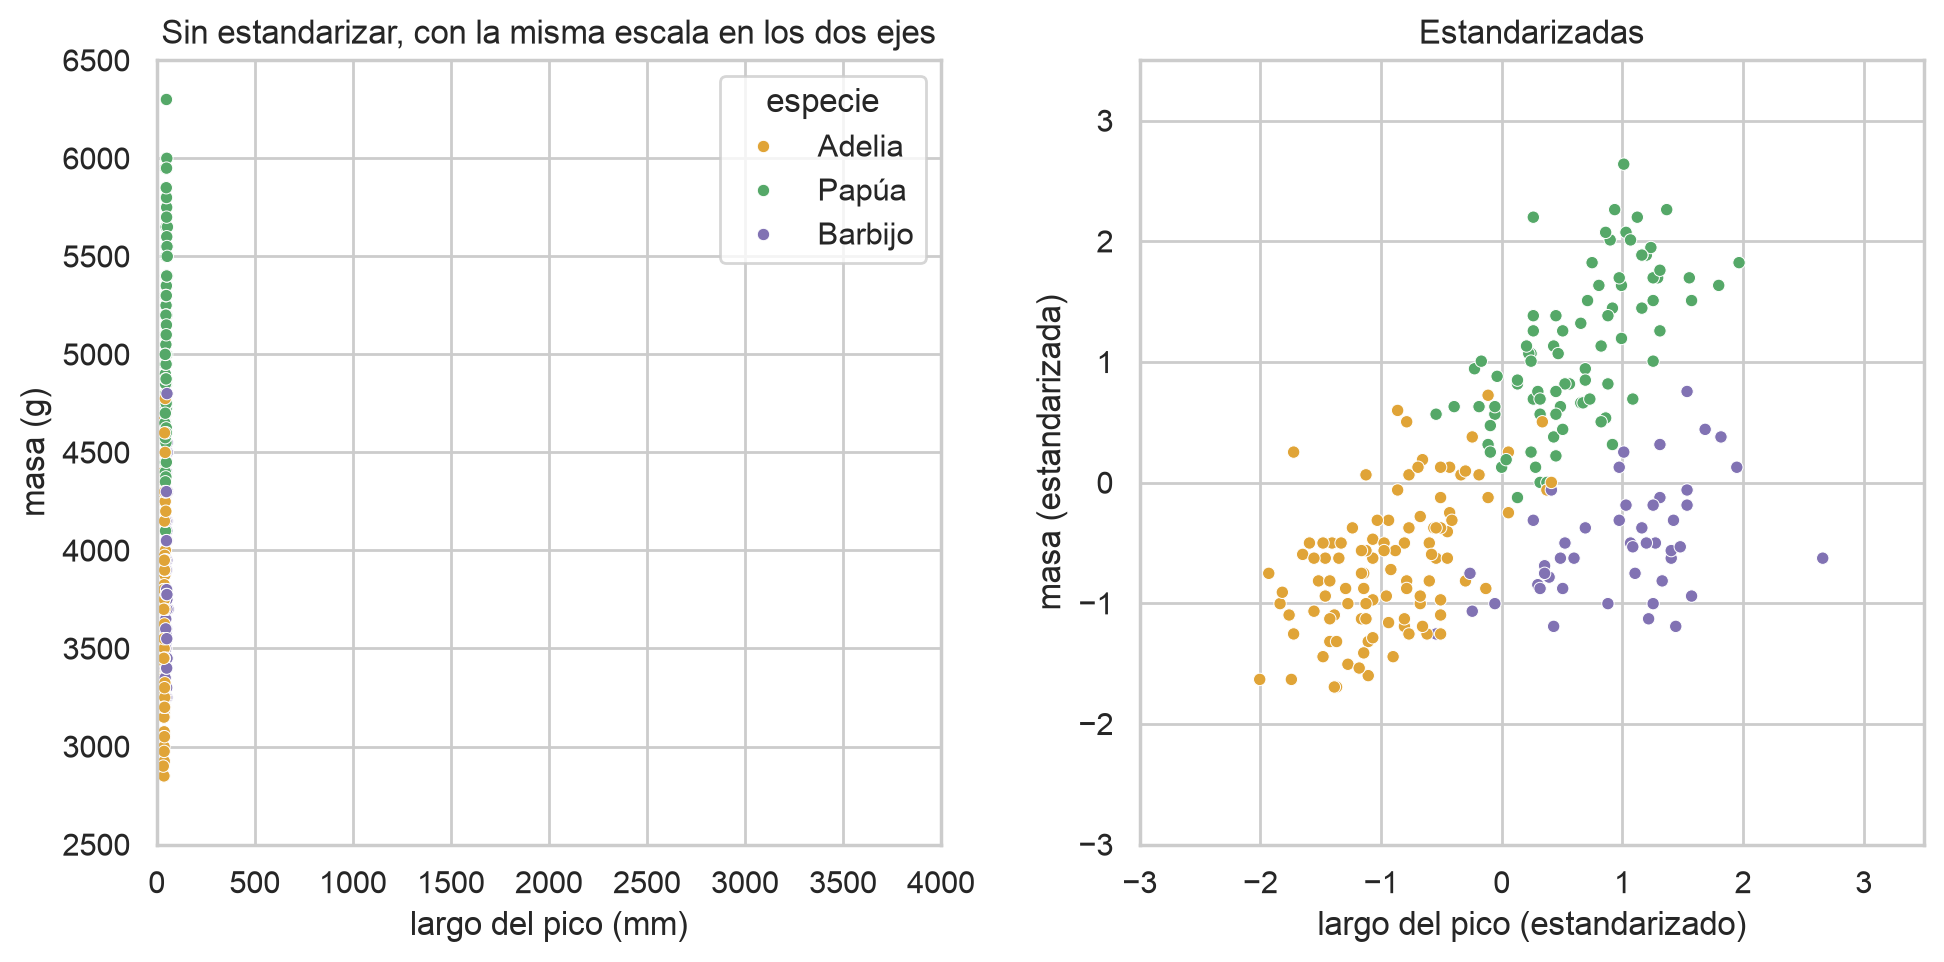

In [17]:
# los mismos pingüinos de entrenamiento y de prueba, con el largo del pico (mm) y la masa (g)
variables = ["largo_pico_mm", "masa_g"]
M_tr = pinguinos.loc[X_tr.index, variables]
M_te = pinguinos.loc[X_te.index, variables]
escala_m = StandardScaler().fit(M_tr)
W_tr = escala_m.transform(M_tr)

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.8))
sns.scatterplot(x=M_tr["largo_pico_mm"], y=M_tr["masa_g"], hue=y_tr, palette=colores, s=20, ax=ejes[0])
ejes[0].set_xlim(0, 4000)       # los dos ejes con el mismo tramo, 4.000 unidades
ejes[0].set_ylim(2500, 6500)
ejes[0].set_xlabel("largo del pico (mm)")
ejes[0].set_ylabel("masa (g)")
ejes[0].set_title("Sin estandarizar, con la misma escala en los dos ejes")

sns.scatterplot(x=W_tr[:, 0], y=W_tr[:, 1], hue=y_tr.values, palette=colores, s=20, ax=ejes[1], legend=False)
ejes[1].set_xlim(-3, 3.5)
ejes[1].set_ylim(-3, 3.5)
ejes[1].set_xlabel("largo del pico (estandarizado)")
ejes[1].set_ylabel("masa (estandarizada)")
ejes[1].set_title("Estandarizadas")

for eje in ejes:
    eje.set_aspect("equal")
plt.tight_layout()
plt.show()

El gráfico de la izquierda muestra los datos como los ve KNN: una fila vertical, donde el largo del pico casi no cuenta. Estandarizadas, las dos variables pesan lo mismo.

In [18]:
sin_estandarizar = KNeighborsClassifier(n_neighbors=5).fit(M_tr, y_tr)
print("sin estandarizar, exactitud en prueba:", exactitud(sin_estandarizar, M_te, y_te))

estandarizado = KNeighborsClassifier(n_neighbors=5).fit(W_tr, y_tr)
print("estandarizado, exactitud en prueba:", exactitud(estandarizado, escala_m.transform(M_te), y_te))

sin estandarizar, exactitud en prueba: 78.6
estandarizado, exactitud en prueba: 95.1


Sin estandarizar, la exactitud en prueba baja de 95,1 % a 78,6 %. Con el largo y el alto del pico el efecto casi no se nota, porque las dos medidas están en milímetros y tienen rangos parecidos.

**El efecto de K.** El mismo clasificador con cinco valores de K.

In [19]:
filas = []
for K in [1, 5, 15, 51, 151]:
    modelo = KNeighborsClassifier(n_neighbors=K).fit(Z_tr, y_tr)
    filas.append({
        "K": K,
        "exactitud_prueba": exactitud(modelo, Z_te, y_te),
    })
efecto_K = pd.DataFrame(filas)
efecto_K

,K,exactitud_prueba
0,1,92.200
1,5,95.100
2,15,94.200
3,51,92.200
4,151,78.600


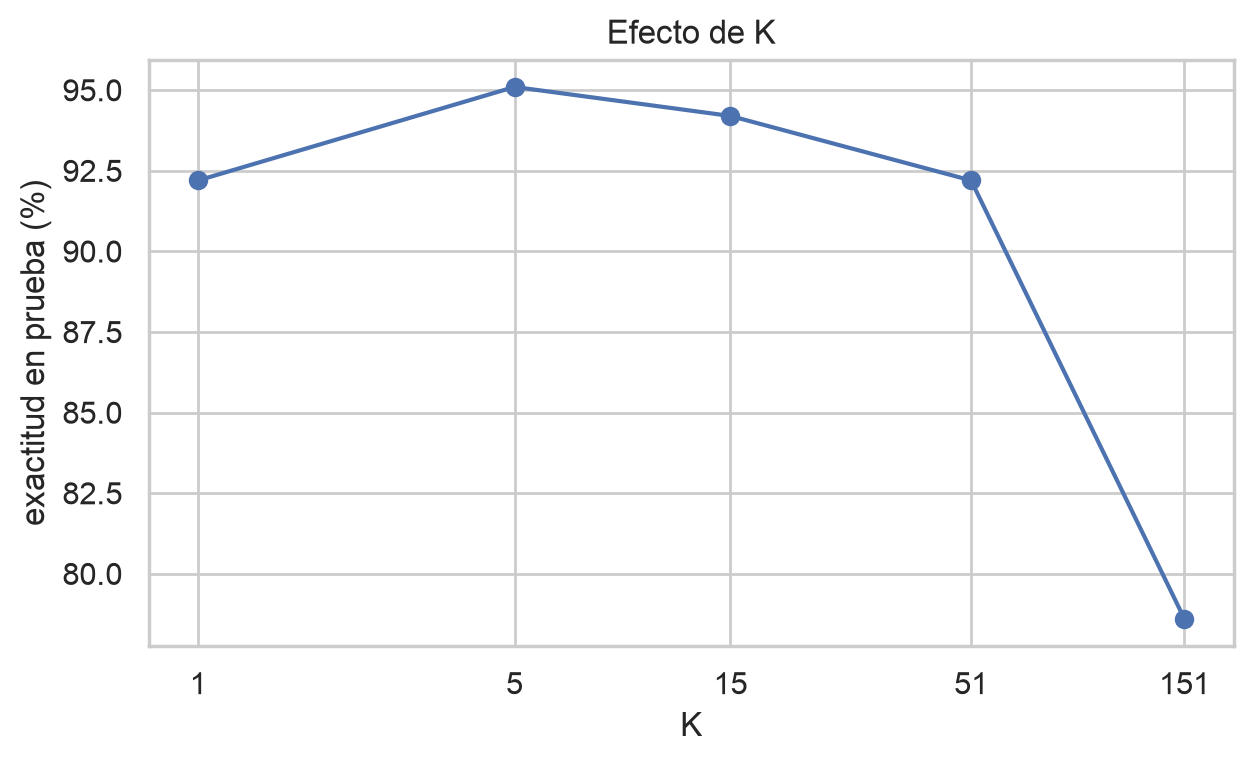

In [20]:
efecto_K.plot(x="K", y="exactitud_prueba", marker="o", logx=True, legend=False, figsize=(7, 3.8))
plt.xticks(efecto_K["K"], efecto_K["K"])
plt.ylabel("exactitud en prueba (%)")
plt.title("Efecto de K")
plt.show()

Con K = 1 decide un solo vecino, y basta uno atípico para equivocarse: 92,2 %. Con K = 5 votan cinco y la exactitud sube a 95,1 %. Con K = 151 votan pingüinos lejanos, de otras especies, y cae a 78,6 %: el modelo quedó demasiado rígido. En KNN la flexibilidad va al revés que K: con K chico el modelo es flexible, y con K grande, rígido.

K no se elige con esta tabla, porque usa la prueba. Se elige con validación cruzada, como C y gamma en la clase 10: se hace más adelante, con los dígitos.

## 4. SVC con tres especies

**Objetivo:** clasificar las tres especies con un SVM, que solo sabe separar dos clases.

`SVC` lo resuelve con la estrategia uno contra uno: ajusta un clasificador por cada par de especies y predice la especie que gana más veces. Se usa el kernel lineal con C = 1, como en la clase 10.

In [21]:
svc = SVC(kernel="linear", C=1).fit(Z_tr, y_tr)
print("especies:", svc.classes_)
print("vectores de soporte por especie:", svc.n_support_)
print("exactitud en entrenamiento:", exactitud(svc, Z_tr, y_tr))
print("exactitud en prueba:", exactitud(svc, Z_te, y_te))

especies: ['Adelia' 'Barbijo' 'Papúa']
vectores de soporte por especie: [10 18  9]
exactitud en entrenamiento: 97.1
exactitud en prueba: 95.1


El SVC acierta el 97,1 % del entrenamiento y el 95,1 % de la prueba, lo mismo que KNN con K = 5 en la prueba. Usa 37 vectores de soporte: 10 Adelia, 18 barbijo y 9 papúa.

**Los tres clasificadores de a pares.** Con tres especies hay tres pares: Adelia contra barbijo, Adelia contra papúa y barbijo contra papúa. Cada par tiene su propia recta, con su β₀ (`intercept_`) y sus β₁ y β₂ (`coef_`), en las medidas estandarizadas.

In [22]:
rectas = pd.DataFrame({
    "clasificador": ["Adelia contra Barbijo", "Adelia contra Papúa", "Barbijo contra Papúa"],
    "b0": svc.intercept_,
    "b1": svc.coef_[:, 0],
    "b2": svc.coef_[:, 1],
})
rectas

,clasificador,b0,b1,b2
0,Adelia contra Barbijo,-0.345,-2.204,1.150
1,Adelia contra Papúa,0.366,-1.312,1.557
2,Barbijo contra Papúa,1.149,-0.943,2.601


**Cómo votan.** Cada clasificador calcula su puntaje f(x) = β₀ + β₁x₁ + β₂x₂ para el pingüino nuevo. Si el puntaje es positivo vota por la primera especie del par, y si es negativo, por la segunda.

In [23]:
x1, x2 = z_nuevo[0]

votos = rectas[["clasificador"]].copy()
votos["puntaje"] = rectas["b0"] + rectas["b1"] * x1 + rectas["b2"] * x2
votos["voto"] = np.where(votos["puntaje"] > 0, ["Adelia", "Adelia", "Barbijo"], ["Barbijo", "Papúa", "Papúa"])

print("predict:", svc.predict(z_nuevo))
votos

predict: ['Barbijo']


,clasificador,puntaje,voto
0,Adelia contra Barbijo,-0.364,Barbijo
1,Adelia contra Papúa,0.089,Adelia
2,Barbijo contra Papúa,0.498,Barbijo


Barbijo gana dos de las tres votaciones, y esa es la predicción de `predict`.

**Las tres rectas.** Cada recta marca los puntos donde el puntaje de un clasificador vale 0.

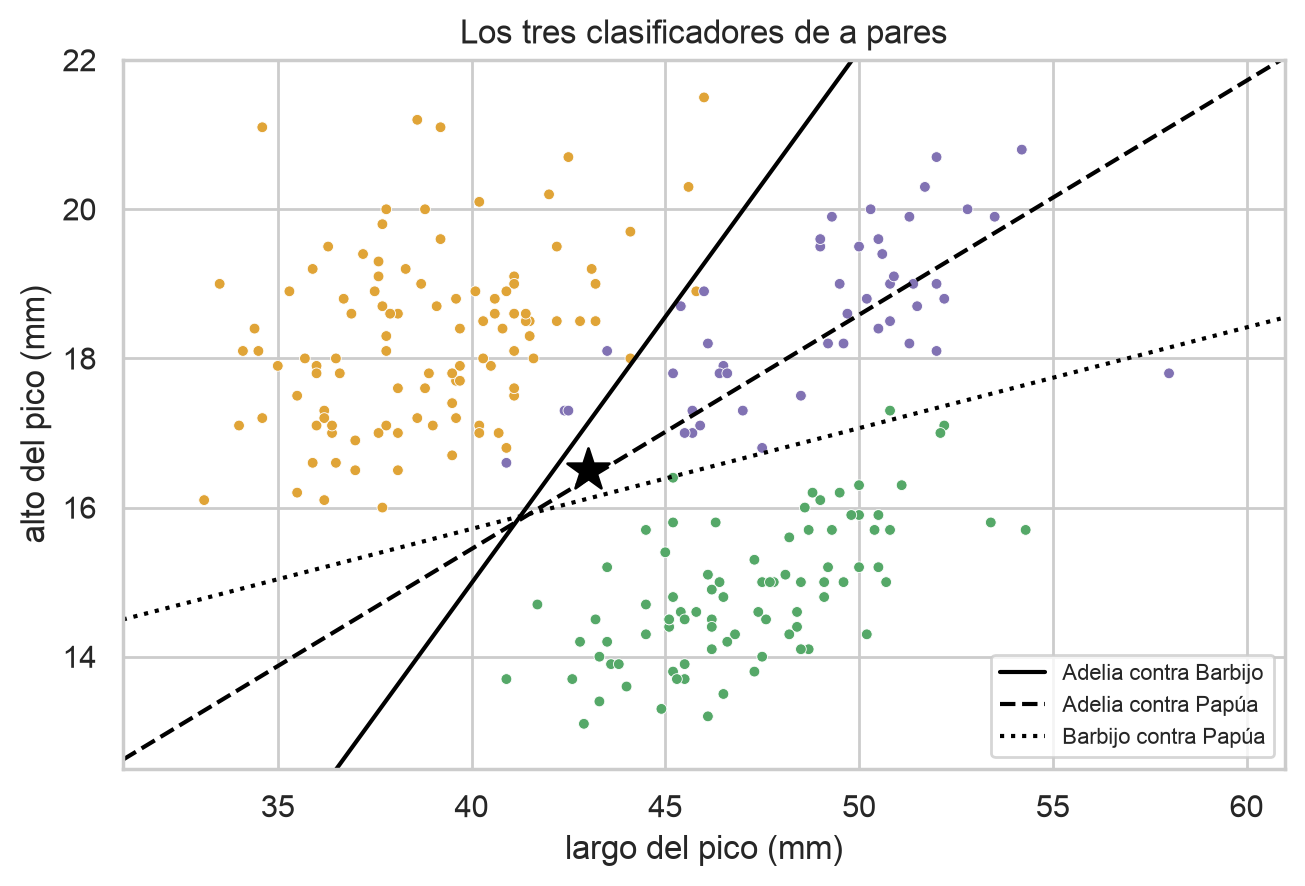

In [24]:
media, desv = escala.mean_, escala.scale_
z1 = np.array([-2.4, 3.2])       # el largo estandarizado, de un extremo al otro del gráfico

fig, eje = plt.subplots(figsize=(7.5, 4.6))
sns.scatterplot(x=X_tr["largo_pico_mm"], y=X_tr["alto_pico_mm"], hue=y_tr, palette=colores, s=15, ax=eje, legend=False)
eje.scatter(nuevo["largo_pico_mm"], nuevo["alto_pico_mm"], marker="*", s=250, color="black")
for i in range(3):
    # la recta del clasificador i: los puntos con puntaje 0, de vuelta en milímetros
    z2 = -(rectas["b0"][i] + rectas["b1"][i] * z1) / rectas["b2"][i]
    eje.plot(media[0] + desv[0] * z1, media[1] + desv[1] * z2, color="black",
             linestyle=["-", "--", ":"][i], label=rectas["clasificador"][i])
eje.set_xlim(31, 61)
eje.set_ylim(12.5, 22)
eje.set_xlabel("largo del pico (mm)")
eje.set_ylabel("alto del pico (mm)")
eje.set_title("Los tres clasificadores de a pares")
eje.legend(loc="lower right", fontsize=8)
plt.show()

## 5. Diez clases: los dígitos

**De tres clases a diez.** Con los pingüinos había tres especies y dos medidas, y por eso todo se podía dibujar. KNN y SVC se usan igual cuando hay más clases y más variables. Lo que cambia es que ya no se puede dibujar el plano, así que el resultado se mira con tablas: la matriz de confusión, la sensibilidad por clase y las curvas ROC.

**Objetivo:** usar KNN y SVC con diez clases y 64 variables, y evaluar el resultado clase por clase.

**Los datos** vienen con scikit-learn: 1.797 imágenes de dígitos escritos a mano, de 8 x 8 píxeles (Alpaydin y Kaynak, 1998). `images` tiene las imágenes, `data` tiene cada imagen estirada en una fila de 64 números y `target` dice qué dígito es. Una imagen es una matriz de 8 x 8: cada número dice cuánta tinta hay en ese píxel, de 0 (nada) a 16. Para los modelos, cada píxel es una variable.

In [25]:
digitos = load_digits()
print("images:", digitos.images.shape)
print("data:", digitos.data.shape)
print("imágenes de cada dígito, del 0 al 9:", np.bincount(digitos.target))

images: (1797, 8, 8)
data: (1797, 64)
imágenes de cada dígito, del 0 al 9: [178 182 177 183 181 182 181 179 174 180]


**La tabla que entra a los modelos.** Igual que con los pingüinos, los modelos reciben una tabla: una fila por imagen y una columna por píxel. `pixel_0_0` es el píxel de la primera fila y la primera columna de la imagen, y `pixel_7_7`, el de la última fila y la última columna. La columna `digito` es la respuesta. Las 64 columnas de píxeles son `digitos.data` y la columna `digito` es `digitos.target`.

In [26]:
# los mismos datos como DataFrame: una fila por imagen, 64 columnas de píxeles y el dígito
tabla_digitos = pd.DataFrame(digitos.data.astype(int), columns=digitos.feature_names)
tabla_digitos["digito"] = digitos.target
print("filas y columnas:", tabla_digitos.shape)
tabla_digitos.head()

filas y columnas: (1797, 65)


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,digito
0,0,0,5,13,9,1,0,0,0,0,...,0,0,0,6,13,10,0,0,0,0
1,0,0,0,12,13,5,0,0,0,0,...,0,0,0,0,11,16,10,0,0,1
2,0,0,0,4,15,12,0,0,0,0,...,0,0,0,0,3,11,16,9,0,2
3,0,0,7,15,13,1,0,0,0,8,...,0,0,0,7,13,13,9,0,0,3
4,0,0,0,1,11,0,0,0,0,0,...,0,0,0,0,2,16,4,0,0,4


La primera fila de la tabla es la primera imagen, estirada. Al ordenar sus 64 números en 8 filas de 8 se recupera la imagen: los números grandes son los píxeles con tinta.

In [27]:
# la primera imagen, como matriz de números
digitos.images[0].astype(int)

array([[ 0,  0,  5, 13,  9,  1,  0,  0],
       [ 0,  0, 13, 15, 10, 15,  5,  0],
       [ 0,  3, 15,  2,  0, 11,  8,  0],
       [ 0,  4, 12,  0,  0,  8,  8,  0],
       [ 0,  5,  8,  0,  0,  9,  8,  0],
       [ 0,  4, 11,  0,  1, 12,  7,  0],
       [ 0,  2, 14,  5, 10, 12,  0,  0],
       [ 0,  0,  6, 13, 10,  0,  0,  0]])

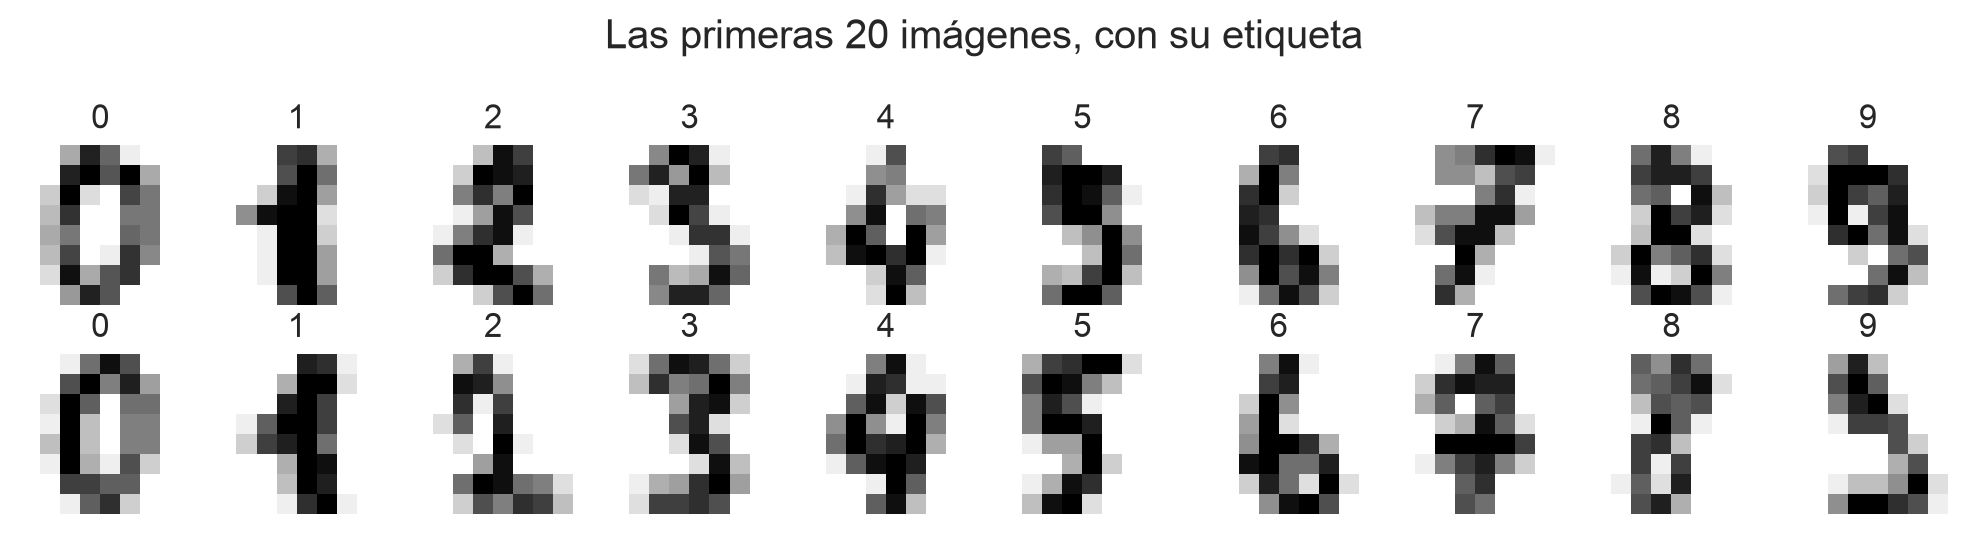

In [28]:
fig, ejes = plt.subplots(2, 10, figsize=(10, 2.8))
for i, eje in enumerate(ejes.ravel()):
    eje.imshow(digitos.images[i], cmap="gray_r")
    eje.set_title(digitos.target[i])
    eje.axis("off")
fig.suptitle("Las primeras 20 imágenes, con su etiqueta")
plt.tight_layout()
plt.show()

**Separar y estandarizar.** El mismo reparto de los pingüinos: 30 % para la prueba, con la misma proporción de cada dígito, y las 64 variables estandarizadas con el entrenamiento.

In [29]:
X_ent, X_pru, y_ent, y_pru = train_test_split(
    digitos.data, digitos.target, test_size=0.3,
    random_state=396, stratify=digitos.target)

escala_d = StandardScaler().fit(X_ent)
Z_ent, Z_pru = escala_d.transform(X_ent), escala_d.transform(X_pru)
print("entrenamiento:", len(X_ent), "imágenes | prueba:", len(X_pru), "imágenes")

entrenamiento: 1257 imágenes | prueba: 540 imágenes


**KNN con imágenes.** La distancia entre dos imágenes se calcula con sus 64 píxeles: dos imágenes están cerca si tienen tinta en los mismos lugares. Estas son la primera imagen de prueba y sus 5 vecinas más cercanas del entrenamiento.

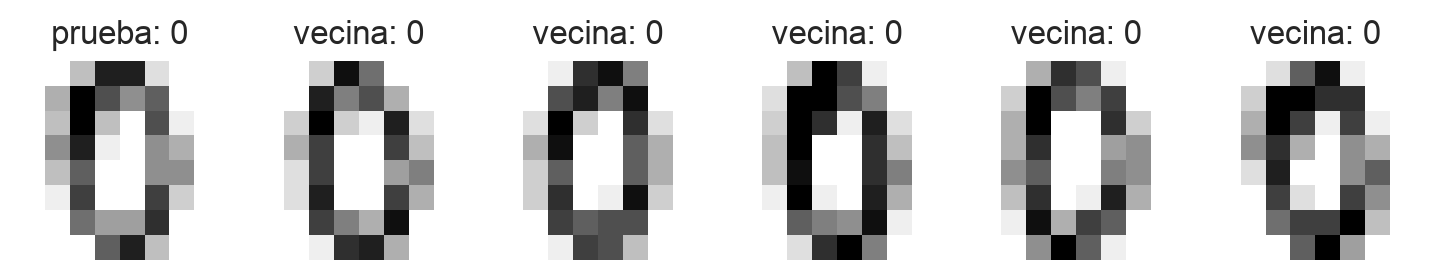

In [30]:
knn_d = KNeighborsClassifier(n_neighbors=5).fit(Z_ent, y_ent)
distancias_d, posiciones_d = knn_d.kneighbors(Z_pru[:1])

fig, ejes = plt.subplots(1, 6, figsize=(9, 1.9))
ejes[0].imshow(X_pru[0].reshape(8, 8), cmap="gray_r")
ejes[0].set_title(f"prueba: {y_pru[0]}")
for eje, p in zip(ejes[1:], posiciones_d[0]):
    eje.imshow(X_ent[p].reshape(8, 8), cmap="gray_r")
    eje.set_title(f"vecina: {y_ent[p]}")
for eje in ejes:
    eje.axis("off")
plt.show()

Las cinco vecinas son imágenes del 0, igual que la de prueba.

**Elegir K.** La misma búsqueda de la sección 3, ahora con los dígitos.

In [31]:
valores_K = [1, 3, 5, 7, 11, 15, 25, 51]
busqueda_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": valores_K}, cv=5).fit(Z_ent, y_ent)

validacion_d = pd.DataFrame({
    "K": valores_K,
    "exactitud_validacion": (100 * busqueda_knn.cv_results_["mean_test_score"]).round(1),
})
print("K elegido:", busqueda_knn.best_params_)
validacion_d

K elegido: {'n_neighbors': 1}


,K,exactitud_validacion
0,1,97.300
1,3,96.700
2,5,96.600
3,7,96.200
4,11,95.300
5,15,94.300
6,25,93.600
7,51,91.000


La validación cruzada elige K = 1, con 97,3 %, y la exactitud baja de forma pareja a medida que K crece.

K = 1, 3 y 5 quedan casi empatados. Para una imagen nueva, la imagen de entrenamiento más parecida casi siempre muestra el mismo número, porque los dígitos casi no se mezclan entre sí; con los pingüinos, que se mezclan en los bordes, K = 1 era peor que K = 5.

**SVC con kernel radial.** Con diez clases, `SVC` ajusta un clasificador por cada par de dígitos: 45 clasificadores. C y gamma se eligen juntos con validación cruzada, como en la clase 10. Cada casilla es la exactitud promedio de los 5 grupos.

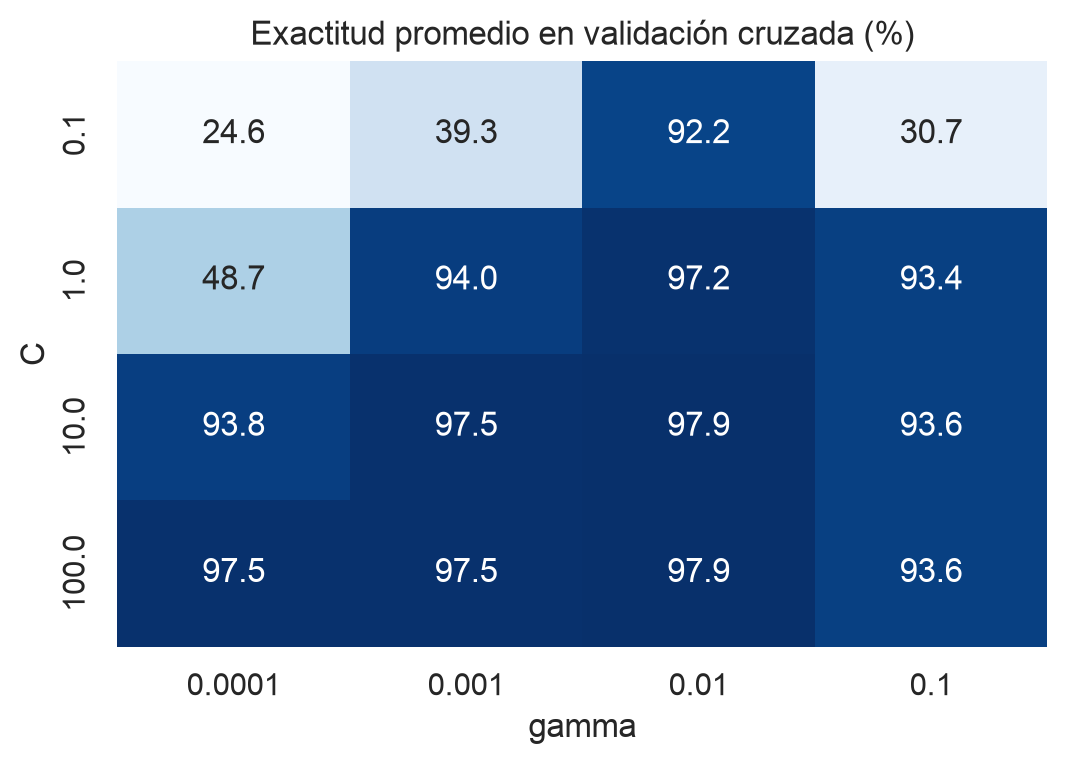

In [32]:
grilla = {"C": [0.1, 1, 10, 100], "gamma": [0.0001, 0.001, 0.01, 0.1]}
busqueda_svc = GridSearchCV(SVC(kernel="rbf"), grilla, cv=5).fit(Z_ent, y_ent)

resultados = pd.DataFrame(busqueda_svc.cv_results_)
tabla_cv = 100 * resultados.pivot(index="param_C", columns="param_gamma", values="mean_test_score")

plt.figure(figsize=(6, 3.8))
sns.heatmap(tabla_cv, annot=True, fmt=".1f", cmap="Blues", cbar=False)
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Exactitud promedio en validación cruzada (%)")
plt.show()

In [33]:
print("mejores parámetros:", busqueda_svc.best_params_)
print("exactitud en validación cruzada:", round(100 * busqueda_svc.best_score_, 1))

# la prueba se usa una sola vez, al final, con los dos modelos elegidos
print("exactitud en prueba, KNN:", exactitud(busqueda_knn, Z_pru, y_pru))
print("exactitud en prueba, SVC:", exactitud(busqueda_svc, Z_pru, y_pru))

mejores parámetros: {'C': 10, 'gamma': 0.01}
exactitud en validación cruzada: 97.9
exactitud en prueba, KNN: 97.0
exactitud en prueba, SVC: 98.3


La validación cruzada elige C = 10 y gamma = 0,01, con 97,9 %. En la prueba, el SVC acierta el 98,3 % y KNN el 97,0 %: son 9 y 16 errores en 540 imágenes.

**La matriz de confusión** del SVC en la prueba. Cada fila es el dígito real y cada columna el predicho. Con diez clases es una tabla de 10 x 10, y los aciertos siguen en la diagonal.

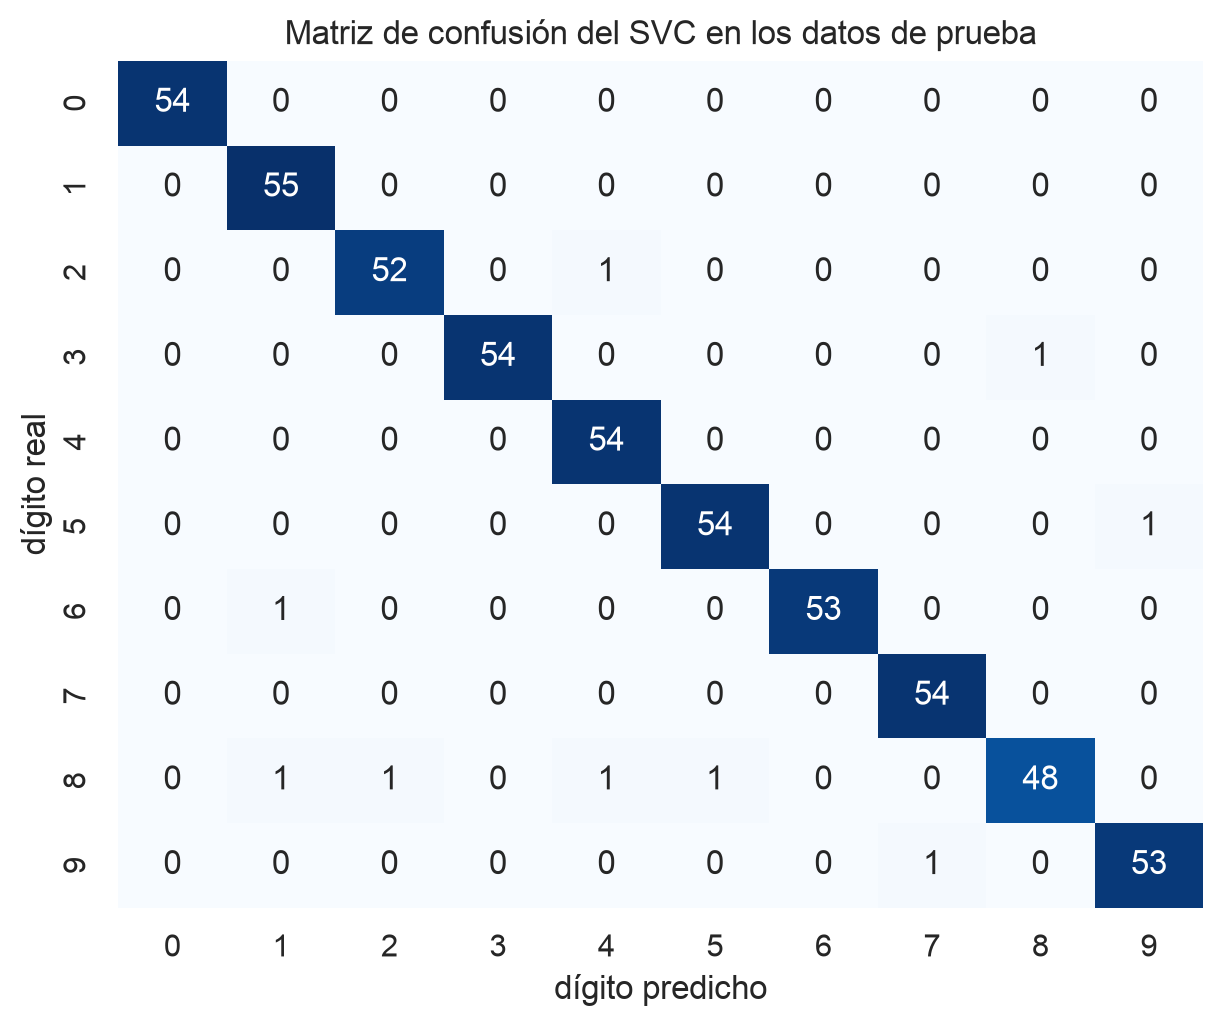

In [34]:
prediccion = busqueda_svc.predict(Z_pru)
matriz = pd.crosstab(y_pru, prediccion, rownames=["dígito real"], colnames=["dígito predicho"])

plt.figure(figsize=(7, 5.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusión del SVC en los datos de prueba")
plt.show()

De los 9 errores, 4 son imágenes del 8, que el modelo confunde con el 1, el 2, el 4 y el 5.

**Sensibilidad y precisión por dígito.** Las medidas de la clase 07, ahora una por clase. La sensibilidad del 8 es la fracción de los 8 reales que el modelo detecta: el acierto de la diagonal dividido por el total de su fila. La precisión del 8 es la fracción de las imágenes predichas como 8 que lo son: el mismo acierto dividido por el total de su columna.

In [35]:
aciertos = np.diag(matriz)
por_digito = pd.DataFrame({
    "digito": range(10),
    "imagenes_reales": matriz.sum(axis=1).values,
    "imagenes_predichas": matriz.sum(axis=0).values,
    "aciertos": aciertos,
    "sensibilidad": aciertos / matriz.sum(axis=1).values,
    "precision": aciertos / matriz.sum(axis=0).values,
})
por_digito

,digito,imagenes_reales,imagenes_predichas,aciertos,sensibilidad,precision
0,0,54,54,54,1.000,1.000
1,1,55,57,55,1.000,0.965
2,2,53,53,52,0.981,0.981
3,3,55,54,54,0.982,1.000
4,4,54,56,54,1.000,0.964
5,5,55,55,54,0.982,0.982
6,6,54,53,53,0.981,1.000
7,7,54,55,54,1.000,0.982
8,8,52,49,48,0.923,0.980
9,9,54,54,53,0.981,0.981


El 8 tiene la sensibilidad más baja, 0,923: de las 52 imágenes del 8, el modelo detecta 48. Las precisiones más bajas son las del 4 y la del 1, cerca de 0,965: en cada caso, dos de las imágenes que el modelo predice con ese dígito son de otro.

**Los errores, dibujados.** Las 9 imágenes de prueba en que el SVC se equivoca.

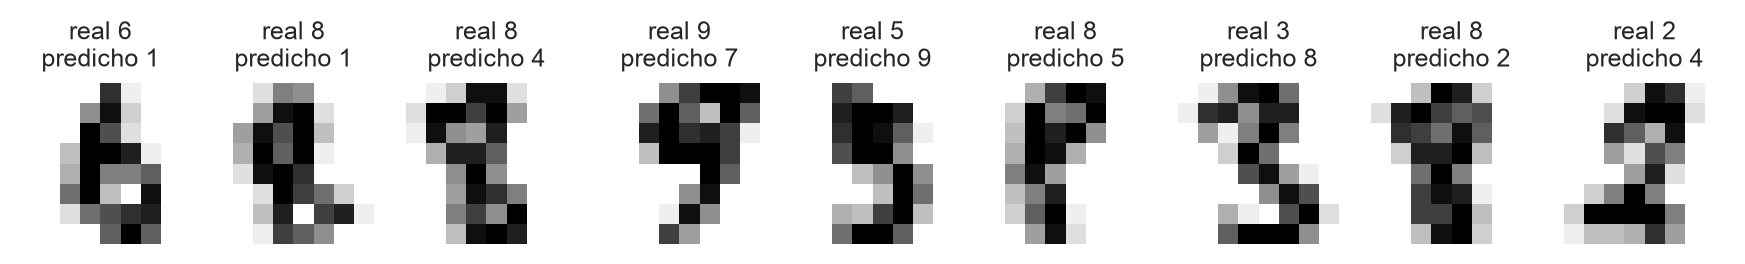

In [36]:
errores = np.where(prediccion != y_pru)[0]

fig, ejes = plt.subplots(1, len(errores), figsize=(11, 2))
for eje, i in zip(ejes, errores):
    eje.imshow(X_pru[i].reshape(8, 8), cmap="gray_r")
    eje.set_title(f"real {y_pru[i]}\npredicho {prediccion[i]}", fontsize=9)
    eje.axis("off")
plt.show()

Con 8 x 8 píxeles, varias de estas imágenes también son difíciles de leer para una persona.

**Curvas ROC por clase.** La curva ROC de la clase 07 es para dos clases. Con diez se dibuja una curva por dígito, uno contra el resto: el 8 contra todo lo que no es 8, y así con cada dígito. Se necesitan dos cosas. `decision_function` entrega, para cada imagen, un puntaje por dígito. Y `label_binarize` arma, para cada dígito, una columna que vale 1 si la imagen es ese dígito y 0 si no. Con la columna de un dígito y sus puntajes, `roc_curve` dibuja la curva y `roc_auc_score` calcula el área bajo ella (AUC), igual que en la clase 07.

In [37]:
puntajes = busqueda_svc.decision_function(Z_pru)
es_digito = label_binarize(y_pru, classes=range(10))
print("puntajes:", puntajes.shape, "| es_digito:", es_digito.shape)

print("primera imagen de prueba, dígito real:", y_pru[0])
print("sus puntajes:", puntajes[0].round(2))
print("su fila en es_digito:", es_digito[0])

puntajes: (540, 10) | es_digito: (540, 10)
primera imagen de prueba, dígito real: 0
sus puntajes: [ 9.31 -0.3   0.73  4.79  2.75  7.26  7.2   1.74  4.23  7.26]
su fila en es_digito: [1 0 0 0 0 0 0 0 0 0]


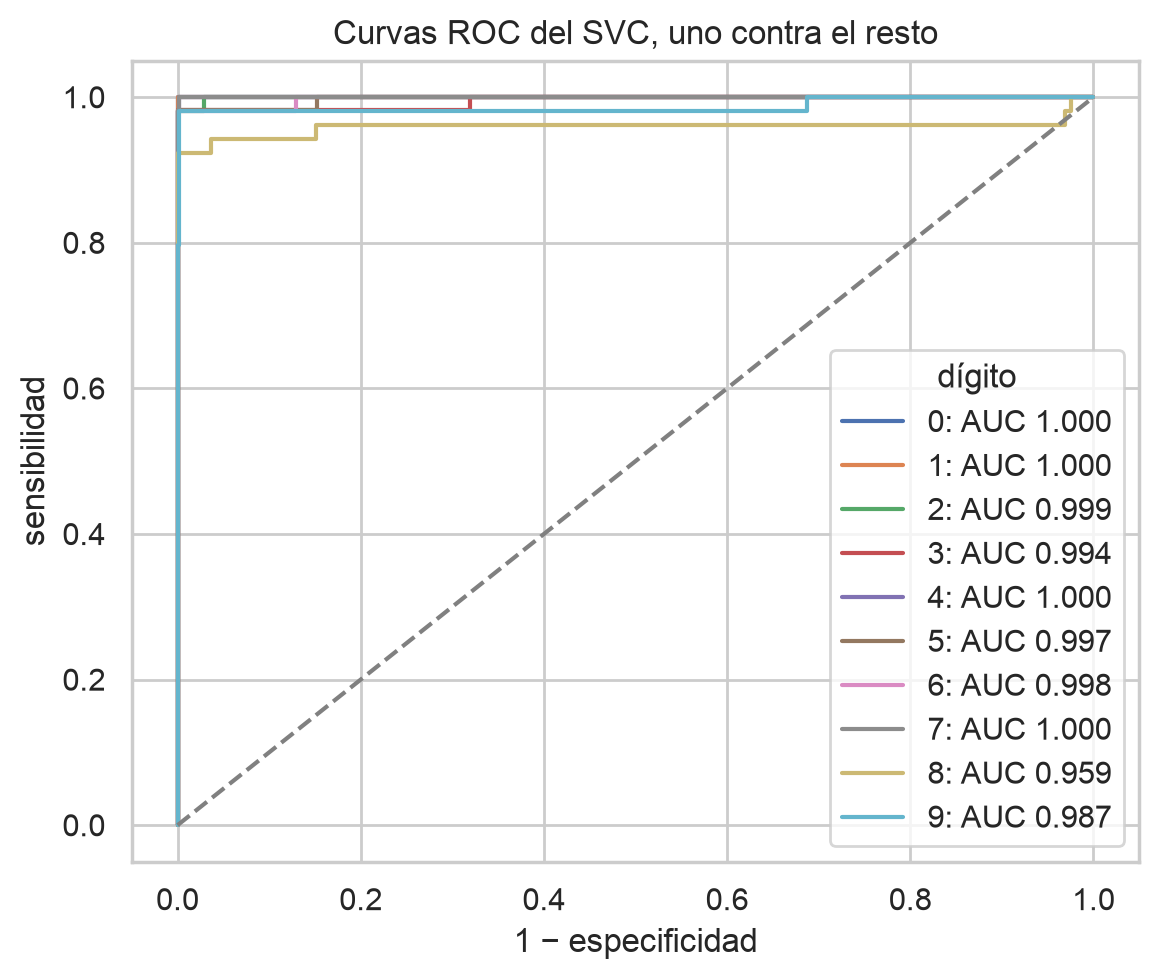

In [38]:
plt.figure(figsize=(6.5, 5.2))
for d in range(10):
    x_roc, y_roc, _ = roc_curve(es_digito[:, d], puntajes[:, d])
    area = roc_auc_score(es_digito[:, d], puntajes[:, d])
    plt.plot(x_roc, y_roc, label=f"{d}: AUC {area:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 − especificidad")
plt.ylabel("sensibilidad")
plt.title("Curvas ROC del SVC, uno contra el resto")
plt.legend(title="dígito")
plt.show()

La primera imagen de prueba es un 0: su puntaje más alto es el del 0, y su fila tiene un 1 en esa posición. Las curvas están pegadas a la esquina superior izquierda: el AUC es 0,994 o más en ocho dígitos y 0,987 en el 9. La del 8 queda más abajo, con AUC 0,959. Es el dígito que más le cuesta al modelo, lo mismo que mostró la matriz de confusión.

## 6. Una red neuronal

**Objetivo:** entrenar una red neuronal pequeña con los mismos dígitos.

`MLPClassifier` arma la red por capas. La capa de entrada son los 64 píxeles, la capa oculta tiene las neuronas que se pidan en `hidden_layer_sizes` (aquí 32) y la capa de salida tiene 10 neuronas, una por dígito. `max_iter` es el máximo de pasadas por los datos de entrenamiento y `random_state` fija los pesos iniciales, que se sortean al azar.

In [39]:
red = MLPClassifier(hidden_layer_sizes=[32], max_iter=2000, random_state=396).fit(Z_ent, y_ent)
print("exactitud en entrenamiento:", exactitud(red, Z_ent, y_ent))
print("exactitud en prueba:", exactitud(red, Z_pru, y_pru))

exactitud en entrenamiento: 100.0
exactitud en prueba: 97.2


La red acierta el 100 % del entrenamiento y el 97,2 % de la prueba.

**La curva de pérdida.** La red no se ajusta de una vez: parte con pesos al azar y los corrige de a poco. En cada pasada por los datos de entrenamiento calcula la pérdida, que es grande cuando las probabilidades que entrega la red están lejos de las etiquetas reales, y mueve los pesos para bajarla. `loss_curve_` guarda la pérdida de cada pasada.

pasadas: 235
pérdida en la primera pasada: 2.52
pérdida en la última pasada: 0.008


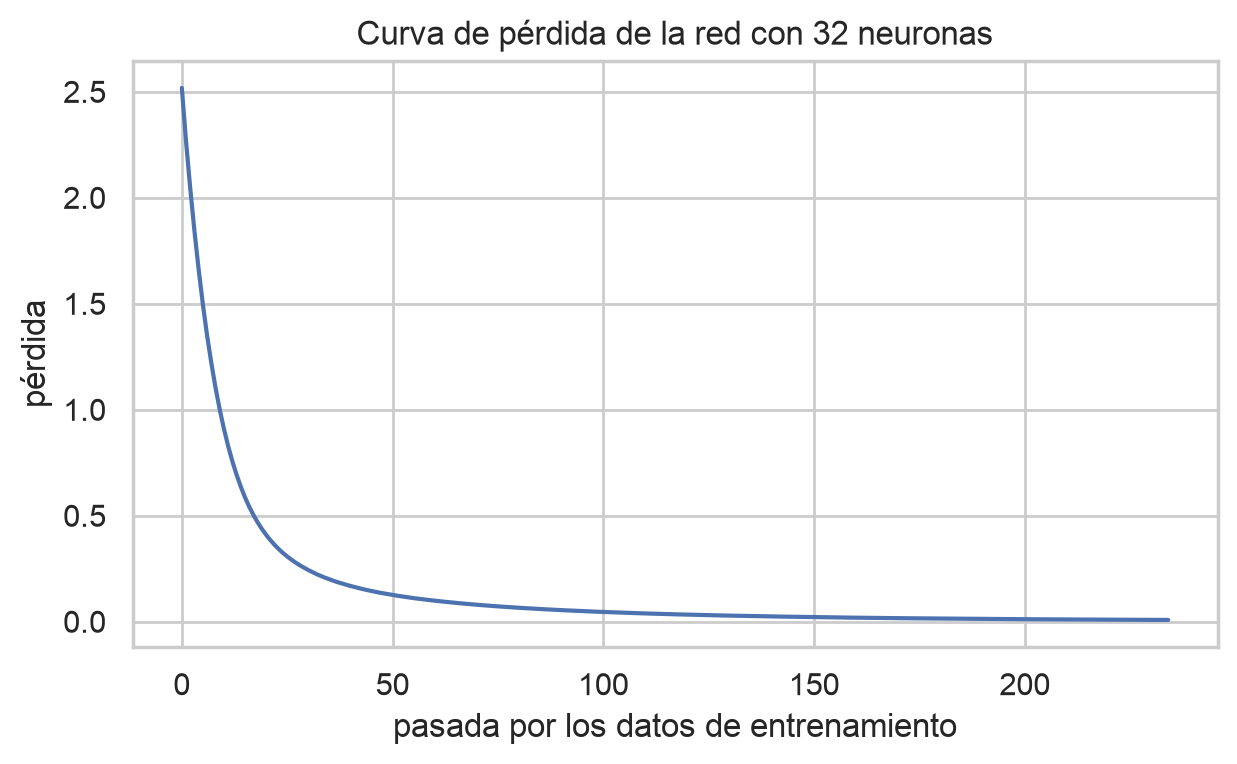

In [40]:
print("pasadas:", red.n_iter_)
print("pérdida en la primera pasada:", round(red.loss_curve_[0], 2))
print("pérdida en la última pasada:", round(red.loss_curve_[-1], 3))

plt.figure(figsize=(7, 3.8))
plt.plot(red.loss_curve_)
plt.xlabel("pasada por los datos de entrenamiento")
plt.ylabel("pérdida")
plt.title("Curva de pérdida de la red con 32 neuronas")
plt.show()

La pérdida baja de 2,52 a 0,008 en 235 pasadas, rápido al principio y lento al final. La red se detiene sola cuando la pérdida deja de mejorar, mucho antes de las 2.000 pasadas que permite `max_iter`.

**Cuántas neuronas.** Como con K, C y gamma: se cambia el número de neuronas de la capa oculta y se mide la exactitud en entrenamiento y en prueba.

In [41]:
filas = []
for neuronas in [2, 8, 32, 128]:
    modelo = MLPClassifier(hidden_layer_sizes=[neuronas], max_iter=2000, random_state=396).fit(Z_ent, y_ent)
    filas.append({
        "neuronas": neuronas,
        "exactitud_entrenamiento": exactitud(modelo, Z_ent, y_ent),
        "exactitud_prueba": exactitud(modelo, Z_pru, y_pru),
    })
efecto_neuronas = pd.DataFrame(filas)
efecto_neuronas

,neuronas,exactitud_entrenamiento,exactitud_prueba
0,2,64.300,60.200
1,8,99.800,94.800
2,32,100.000,97.200
3,128,100.000,98.100


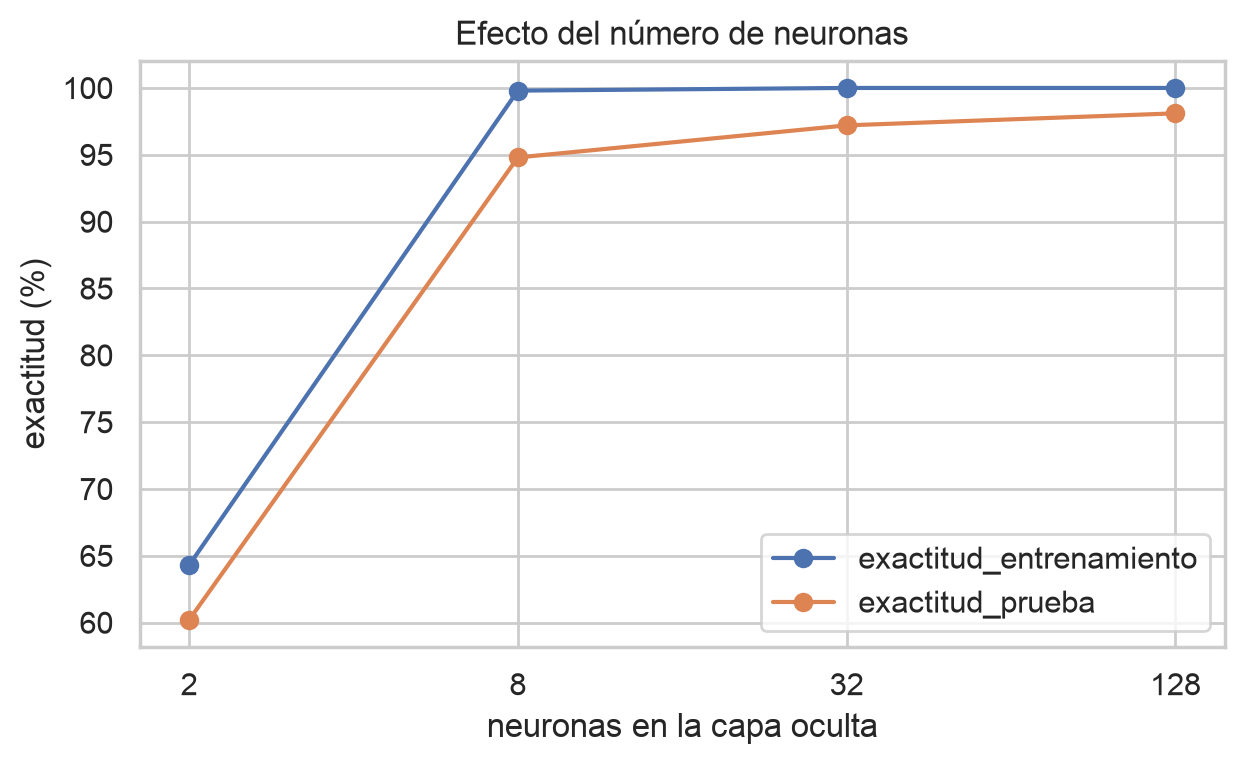

In [42]:
efecto_neuronas.plot(x="neuronas", y=["exactitud_entrenamiento", "exactitud_prueba"], marker="o", logx=True, figsize=(7, 3.8))
plt.xticks(efecto_neuronas["neuronas"], efecto_neuronas["neuronas"])
plt.xlabel("neuronas en la capa oculta")
plt.ylabel("exactitud (%)")
plt.title("Efecto del número de neuronas")
plt.show()

Con 2 neuronas la red no alcanza: acierta el 64,3 % del entrenamiento y el 60,2 % de la prueba. Con 8 ya llega a 94,8 % en la prueba, con 32 a 97,2 % y con 128 a 98,1 %.

**Los pesos.** Lo que la red aprende son números, guardados en matrices. `coefs_` tiene una matriz de pesos por cada par de capas seguidas: la primera conecta los 64 píxeles con las 32 neuronas de la capa oculta, y la segunda conecta esas 32 neuronas con las 10 de salida. `intercepts_` tiene la constante de cada neurona. En total son 2.410 números, todos ajustados durante el entrenamiento.

In [43]:
for pesos, constantes in zip(red.coefs_, red.intercepts_):
    print("pesos:", pesos.shape, "| constantes:", constantes.shape)

print("números que ajusta la red:", 64 * 32 + 32 + 32 * 10 + 10)

pesos: (64, 32) | constantes: (32,)
pesos: (32, 10) | constantes: (10,)
números que ajusta la red: 2410


## 7. Los tres clasificadores juntos

Los tres modelos, con los mismos datos de entrenamiento y de prueba de los dígitos.

In [44]:
modelos = {
    "KNN, K = 1": busqueda_knn,
    "SVC radial, C = 10 y gamma = 0,01": busqueda_svc,
    "red neuronal, 32 neuronas": red,
}
filas = []
for nombre, modelo in modelos.items():
    filas.append({
        "modelo": nombre,
        "exactitud_entrenamiento": exactitud(modelo, Z_ent, y_ent),
        "exactitud_prueba": exactitud(modelo, Z_pru, y_pru),
        "errores_prueba": (modelo.predict(Z_pru) != y_pru).sum(),
    })
pd.DataFrame(filas)

,modelo,exactitud_entrenamiento,exactitud_prueba,errores_prueba
0,"KNN, K = 1",100.000,97.000,16
1,"SVC radial, C = 10 y gamma = 0,01",100.000,98.300,9
2,"red neuronal, 32 neuronas",100.000,97.200,15


Los tres aciertan el 97 % o más de la prueba: entre 9 y 16 errores en 540 imágenes. El SVC queda un poco más arriba, pero entre el primero y el último hay 7 imágenes de diferencia.

---

**Próximas fechas.** El viernes 27 de noviembre es el Certamen 2, con las unidades 6 a 9. La Tarea 3 se entrega el martes 1 de diciembre por Aula. El viernes 4 de diciembre son las presentaciones del proyecto final.